<a href="https://colab.research.google.com/github/IvMatic/fraud-ring-detection-ml/blob/main/notebooks/02_isolation_forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# 02 — Isolation Forest Anomaly Detection

## Objective
Train an Isolation Forest model to detect unusual
bank account behavior using synthetic account features.

## Research Question
Can Isolation Forest identify anomalous accounts
without using anomaly labels during training?

## Dataset
Synthetic Account Anomaly Dataset v1

## Reference
Liu, F. T., Ting, K. M., & Zhou, Z.-H. (2008).
Isolation Forest.
https://doi.org/10.1109/ICDM.2008.17


In [1]:

from google.colab import drive
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest

drive.mount("/content/drive")

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/fraud-ring-detection-ml"
)

DATA_PATH = (
    PROJECT_ROOT / "data/raw/synthetic_accounts_v1.csv"
)

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())


Mounted at /content/drive
Dataset shape: (1000, 5)


,account_id,num_devices,num_transactions_24h,connected_accounts,is_synthetic_anomaly
0,ACC_00001,0,12,5,0
1,ACC_00002,0,17,4,0
2,ACC_00003,3,9,1,0
3,ACC_00004,2,9,4,0
4,ACC_00005,2,9,4,0


In [2]:

FEATURES = [
    "num_devices",
    "num_transactions_24h",
    "connected_accounts"
]

X = df[FEATURES].copy()

print("Training data shape:", X.shape)
display(X.head())


Training data shape: (1000, 3)


,num_devices,num_transactions_24h,connected_accounts
0,0,12,5
1,0,17,4
2,3,9,1
3,2,9,4
4,2,9,4


In [3]:

model = IsolationForest(
    n_estimators=100,
    max_samples="auto",
    contamination=0.03,
    random_state=42
)

model.fit(X)

print("Isolation Forest model trained successfully!")


Isolation Forest model trained successfully!


In [4]:

# Predict anomalies
df["prediction"] = model.predict(X)

# Calculate anomaly scores
df["anomaly_score"] = -model.score_samples(X)

# Convert predictions:
# -1 = anomaly, 1 = normal
df["predicted_anomaly"] = (
    df["prediction"] == -1
).astype(int)

print("Prediction distribution:")
print(df["predicted_anomaly"].value_counts())

# Show 10 most anomalous accounts
display(
    df.sort_values(
        "anomaly_score",
        ascending=False
    ).head(10)
)


Prediction distribution:
predicted_anomaly
0    970
1     30
Name: count, dtype: int64


,account_id,num_devices,num_transactions_24h,connected_accounts,is_synthetic_anomaly,prediction,anomaly_score,predicted_anomaly
117,ACC_00118,19,98,54,1,-1,0.799355,1
662,ACC_00663,16,129,23,1,-1,0.795578,1
399,ACC_00400,18,118,37,1,-1,0.789679,1
86,ACC_00087,18,68,23,1,-1,0.788078,1
251,ACC_00252,18,67,50,1,-1,0.788078,1
754,ACC_00755,11,144,59,1,-1,0.784885,1
518,ACC_00519,17,109,30,1,-1,0.778538,1
133,ACC_00134,8,142,44,1,-1,0.775909,1
152,ACC_00153,15,80,59,1,-1,0.772243,1
112,ACC_00113,9,145,42,1,-1,0.768594,1


In [5]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

y_true = df["is_synthetic_anomaly"]
y_pred = df["predicted_anomaly"]

cm = confusion_matrix(y_true, y_pred)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        digits=3,
        zero_division=0
    )
)


Confusion Matrix:
[[970   0]
 [  0  30]]

Classification Report:
              precision    recall  f1-score   support

           0      1.000     1.000     1.000       970
           1      1.000     1.000     1.000        30

    accuracy                          1.000      1000
   macro avg      1.000     1.000     1.000      1000
weighted avg      1.000     1.000     1.000      1000



In [6]:

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

X_train, X_test, y_train, y_test = train_test_split(
    df[FEATURES],
    df["is_synthetic_anomaly"],
    test_size=0.2,
    random_state=42,
    stratify=df["is_synthetic_anomaly"]
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

print("Train anomalies:", y_train.sum())
print("Test anomalies:", y_test.sum())


Train: (800, 3)
Test: (200, 3)
Train anomalies: 24
Test anomalies: 6


In [7]:

model_test = IsolationForest(
    n_estimators=100,
    max_samples="auto",
    contamination=0.03,
    random_state=42
)

model_test.fit(X_train)

# Predict on unseen test data
test_predictions = (
    model_test.predict(X_test) == -1
).astype(int)

print("Test Confusion Matrix:")
print(confusion_matrix(y_test, test_predictions))

print("\nTest Classification Report:")
print(
    classification_report(
        y_test,
        test_predictions,
        digits=3,
        zero_division=0
    )
)


Test Confusion Matrix:
[[194   0]
 [  0   6]]

Test Classification Report:
              precision    recall  f1-score   support

           0      1.000     1.000     1.000       194
           1      1.000     1.000     1.000         6

    accuracy                          1.000       200
   macro avg      1.000     1.000     1.000       200
weighted avg      1.000     1.000     1.000       200



In [8]:

from sklearn.metrics import precision_score, recall_score, f1_score

contamination_values = [0.01, 0.02, 0.03, 0.05, 0.10]

results = []

for contamination in contamination_values:

    model_exp = IsolationForest(
        n_estimators=100,
        max_samples="auto",
        contamination=contamination,
        random_state=42
    )

    model_exp.fit(X_train)

    y_pred = (
        model_exp.predict(X_test) == -1
    ).astype(int)

    results.append({
        "contamination": contamination,
        "predicted_anomalies": int(y_pred.sum()),
        "precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "f1_score": f1_score(
            y_test, y_pred, zero_division=0
        )
    })

results_df = pd.DataFrame(results)

display(results_df)


,contamination,predicted_anomalies,precision,recall,f1_score
0,0.01,3,1.0,0.500000,0.666667
1,0.02,5,1.0,0.833333,0.909091
2,0.03,6,1.0,1.000000,1.000000
3,0.05,10,0.6,1.000000,0.750000
4,0.10,15,0.4,1.000000,0.571429


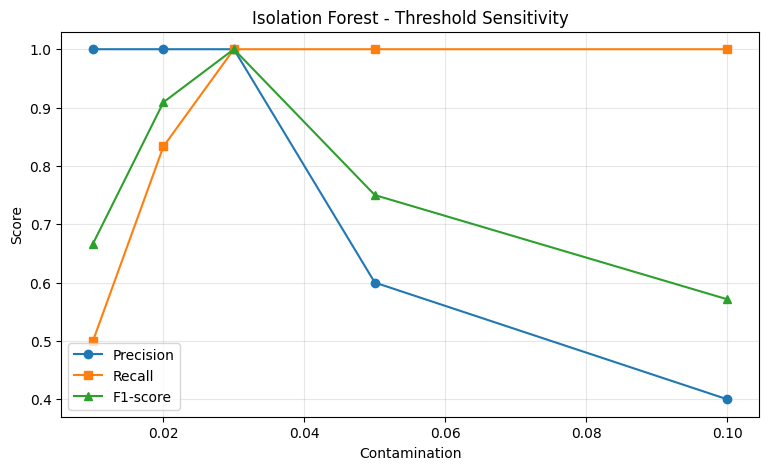

In [9]:

plt.figure(figsize=(9, 5))

plt.plot(
    results_df["contamination"],
    results_df["precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    results_df["contamination"],
    results_df["recall"],
    marker="s",
    label="Recall"
)

plt.plot(
    results_df["contamination"],
    results_df["f1_score"],
    marker="^",
    label="F1-score"
)

plt.xlabel("Contamination")
plt.ylabel("Score")
plt.title("Isolation Forest - Threshold Sensitivity")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
